# 12 · Monitoring report: the go-live replay

The monitoring tables over the replayed period, as charts: how well the models ranked the areas (P0), whether their inputs and outputs drifted (PSI, CSI), whether what drives them changed (attribution nDCG), whether some areas were served worse (the fairness gap), and what the pipeline did about it (promote, retrain, roll back).

In [1]:
import json
import os
from datetime import timedelta

import matplotlib.pyplot as plt
import pandas as pd
import yaml

# run from the repo root, where main.py, config/ and datamart/ are
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from utils.tables import read_table

with open("config/pipeline.yaml") as f:
    config = yaml.safe_load(f)

performance = read_table("monitoring/model_performance", config)
stability = read_table("monitoring/stability", config)
attribution = read_table("monitoring/attribution", config)
actions = read_table("monitoring/actions", config)
with open(os.path.join(config["paths"]["model_bank"], "registry.json")) as f:
    registry = json.load(f)
days = performance.loc[performance["granularity"] == "day", "period_start"]
print(f"monitored days: {days.nunique()}, {days.min():%d %b %Y} to {days.max():%d %b %Y}")
# date: the labelled day the action was decided on (at is when the replay wrote it)
events = actions[actions["action"].isin(["promote", "rollback", "retrain"])]
events[["date", "action", "model_version", "reason", "evidence"]]

monitored days: 242, 01 Jan 2023 to 30 Aug 2023


,date,action,model_version,reason,evidence
11,2023-01-31,promote,M2_2021_12_20261027T163527,shadow ahead of B0_2021_12_20261014T050309 by ...,"rolling P0 production 0.279, shadow 0.299"


## 1 · P0 over time

The share of each shift's crashes in the 10 areas forecast highest. Dots: one day; lines: the rolling 28 days, per model and role. The dashed lines mark the actions. A 28-day line starts once a model has forecast 28 whole days in that role, so after a promotion there are no lines for 28 days.

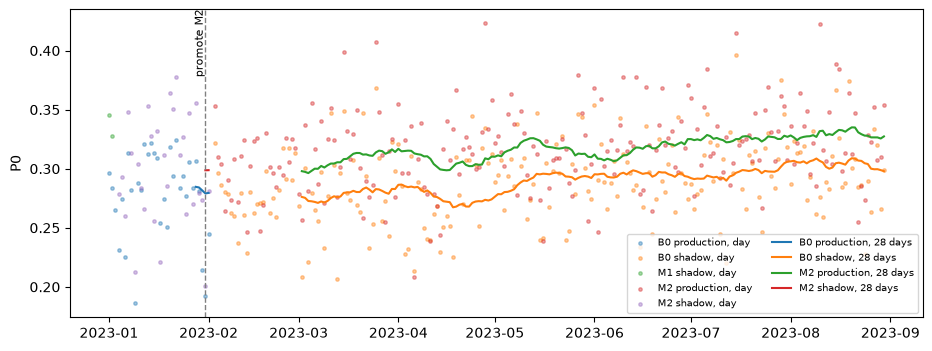

In [2]:
p0 = performance[(performance["metric"] == "P0") & (performance["segment"] == "citywide")]
day = p0[p0["granularity"] == "day"]
# a day split between two models in one role (the day after a swap, when the old model served the 00:00
# hour; 3 January, when M2 took over the shadow) gives each a few hours' P0: left out of the dots
models_in_role = day.groupby(["period_start", "role"])["model_version"].transform("nunique")
day = day[models_in_role == 1]
fig, ax = plt.subplots(figsize=(11, 4))
for (model_version, role), rows in day.groupby(["model_version", "role"]):
    ax.scatter(rows["period_start"], rows["value"], s=6, alpha=0.4, label=f"{model_version[:2]} {role}, day")
for (model_version, role), rows in p0[p0["granularity"] == "rolling_28d"].groupby(["model_version", "role"]):
    rows = rows.sort_values("period_end")
    ax.plot(rows["period_end"] - timedelta(days=1), rows["value"], label=f"{model_version[:2]} {role}, 28 days")
for r in events.itertuples():
    ax.axvline(pd.Timestamp(str(r.date)), color="grey", linestyle="--", linewidth=1)
    ax.annotate(f"{r.action} {r.model_version[:2]}", (pd.Timestamp(str(r.date)), ax.get_ylim()[1]),
                rotation=90, va="top", ha="right", fontsize=8)
ax.set_ylabel("P0")
ax.legend(fontsize=7, ncol=2, loc="lower right")
plt.show()

## 2 · Stability: the forecasts (PSI) and the inputs (CSI) over the last week

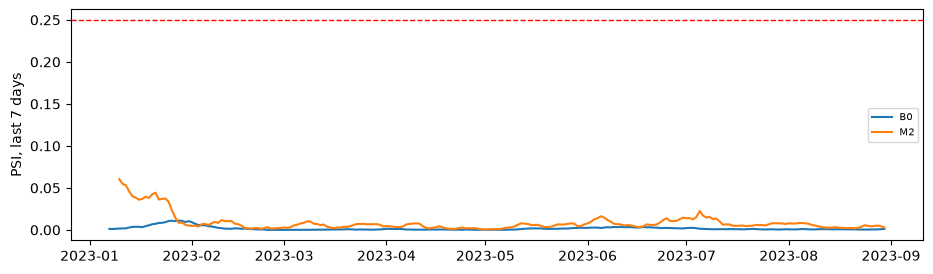

,median,max
variable,,
wx_temp_c,4.023,7.455
wx_dew_point_c,4.215,6.661
crash_city_notified_24h,1.898,5.300
taxi_city_trips_1h,2.322,2.997
wx_visibility_m,0.094,2.523
wx_wind_ms,0.206,1.369
crash_city_notified_3h,0.064,0.475
crash_city_how_mean_4w,0.057,0.324
crash_city_notified_1h,0.061,0.238


In [3]:
psi = stability[stability["index"] == "PSI"]
fig, ax = plt.subplots(figsize=(11, 3))
for model_version, rows in psi.groupby("model_version"):
    rows = rows.sort_values("period_end")
    ax.plot(rows["period_end"] - timedelta(days=1), rows["value"], label=model_version[:2])
ax.axhline(config["monitoring"]["psi"]["alert"], color="red", linestyle="--", linewidth=1)
ax.set_ylabel("PSI, last 7 days")
ax.legend(fontsize=7)
plt.show()

csi = stability[stability["index"] == "CSI"]
csi.groupby("variable")["value"].agg(["median", "max"]).sort_values("max", ascending=False).head(10).round(3)

## 3 · Feature attribution: does each model still lean on the same features? (nDCG, alert below 0.9)

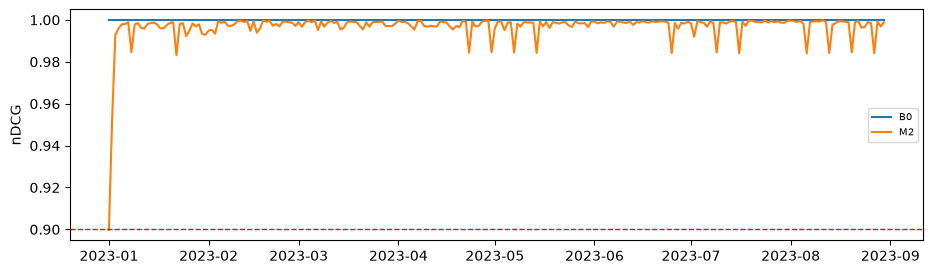

In [4]:
ndcg = attribution[attribution["feature"] == "__ndcg__"]
fig, ax = plt.subplots(figsize=(11, 3))
for model_version, rows in ndcg.groupby("model_version"):
    rows = rows.sort_values("period_start")
    ax.plot(rows["period_start"], rows["value"], label=model_version[:2])
ax.axhline(config["monitoring"]["attribution_ndcg"], color="red", linestyle="--", linewidth=1)
ax.set_ylabel("nDCG")
ax.legend(fontsize=7)
plt.show()

## 4 · Fairness: the P0 gap between the high-taxi-coverage areas and the rest

For the production model each day, and its 28-day mean. The busiest areas fill the top 10, so a gap is expected; an alert means it widened beyond the gap on validation.

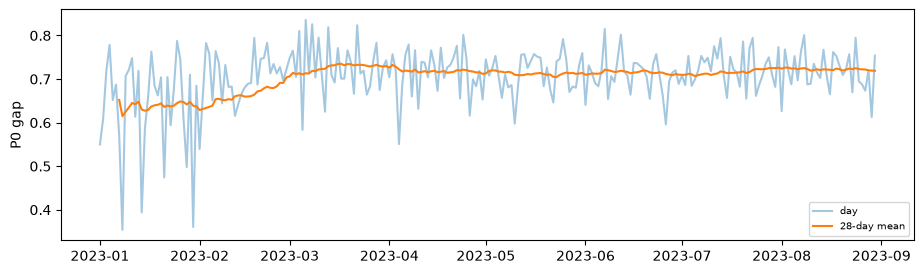

In [5]:
groups = performance[(performance["granularity"] == "day") & (performance["metric"] == "P0")
                     & (performance["role"] == "production")
                     & performance["segment"].isin(["high_taxi_coverage", "other_areas"])]
# the day after a swap has two production models (the old one served its 00:00 hour): left out
models_a_day = groups.groupby("period_start")["model_version"].nunique()
groups = groups[groups["period_start"].map(models_a_day) == 1]
gap = (groups.pivot_table(index="period_start", columns="segment", values="value")
       .eval("high_taxi_coverage - other_areas").rename("gap"))
fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(gap.index, gap, alpha=0.4, label="day")
ax.plot(gap.index, gap.rolling(28, min_periods=7).mean(), label="28-day mean")
ax.set_ylabel("P0 gap")
ax.legend(fontsize=7)
plt.show()

## 5 · What the pipeline did: actions and the registry

In [6]:
print(actions["action"].value_counts().to_string())
history = pd.DataFrame([{"model_version": e["model_version"], **h} for e in registry for h in e["status_history"]])
history[history["status"] != "candidate"].sort_values("at")[["at", "model_version", "status", "reason"]]

action
alert      11
promote     1


,at,model_version,status,reason
1,2026-10-14T05:03:09,B0_2021_12_20261014T050309,production,first deployment: the baseline serves first
4,2026-10-14T05:03:09,M1_2021_12_20261014T050309,shadow,first deployment: best other candidate by test P0
5,2026-10-27T16:35:27,M1_2021_12_20261014T050309,archived,replaced in shadow by M2_2021_12_20261027T163527
7,2026-10-27T16:35:27,B0_2021_12_20261027T163527,rejected,the baseline: it sets the bar for the others
9,2026-10-27T16:35:27,M1_2021_12_20261027T163527,rejected,not selected: M2_2021_12_20261027T163527 was s...
11,2026-10-27T16:35:27,M2_2021_12_20261027T163527,shadow,"selected: validation P0 0.305, B0 0.276"
2,2026-10-27T18:14:41,B0_2021_12_20261014T050309,shadow,demoted by M2_2021_12_20261027T163527: rolling...
12,2026-10-27T18:14:41,M2_2021_12_20261027T163527,production,promoted over B0_2021_12_20261014T050309: roll...


## 6 · Month by month (scored on the 10th of the next month)

In [7]:
months = performance[(performance["granularity"] == "month") & (performance["segment"] == "citywide")]
months.pivot_table(index=["period_start", "model_version", "role"], columns="metric", values="value").round(3)

metric                                                MAE     P0   RMSE  \
period_start model_version              role                              
2023-01-01   B0_2021_12_20261014T050309 production  0.215  0.279  0.418   
             M1_2021_12_20261014T050309 shadow      0.193  0.349  0.334   
             M2_2021_12_20261027T163527 shadow      0.213  0.298  0.374   
2023-02-01   B0_2021_12_20261014T050309 production  0.225  0.183  0.437   
                                        shadow      0.227  0.279  0.433   
             M2_2021_12_20261027T163527 production  0.228  0.299  0.387   
                                        shadow      0.231  0.211  0.393   
2023-03-01   B0_2021_12_20261014T050309 shadow      0.231  0.281  0.438   
             M2_2021_12_20261027T163527 production  0.228  0.312  0.390   
2023-04-01   B0_2021_12_20261014T050309 shadow      0.235  0.276  0.442   
             M2_2021_12_20261027T163527 production  0.234  0.311  0.396   
2023-05-01   B0_2021_12_20261014T050309 shadow      0.248  0.293  0.463   
             M2_2021_12_20261027T163527 production  0.247  0.311  0.413   
2023-06-01   B0_2021_12_20261014T050309 shadow      0.249  0.295  0.458   
             M2_2021_12_20261027T163527 production  0.247  0.324  0.408   
2023-07-01   B0_2021_12_20261014T050309 shadow      0.241  0.303  0.445   
             M2_2021_12_20261027T163527 production  0.240  0.327  0.398   

metric                                               bias  poisson_deviance  
period_start model_version              role                                 
2023-01-01   B0_2021_12_20261014T050309 production  1.071             1.001  
             M1_2021_12_20261014T050309 shadow      1.263             0.458  
             M2_2021_12_20261027T163527 shadow      1.031             0.494  
2023-02-01   B0_2021_12_20261014T050309 production  0.850             1.130  
                                        shadow      1.045             1.044  
             M2_2021_12_20261027T163527 production  1.045             0.516  
                                        shadow      0.953             0.521  
2023-03-01   B0_2021_12_20261014T050309 shadow      1.083             1.032  
             M2_2021_12_20261027T163527 production  1.046             0.512  
2023-04-01   B0_2021_12_20261014T050309 shadow      1.029             1.056  
             M2_2021_12_20261027T163527 production  1.022             0.524  
2023-05-01   B0_2021_12_20261014T050309 shadow      1.041             1.080  
             M2_2021_12_20261027T163527 production  1.028             0.540  
2023-06-01   B0_2021_12_20261014T050309 shadow      1.106             1.056  
             M2_2021_12_20261027T163527 production  1.081             0.537  
2023-07-01   B0_2021_12_20261014T050309 shadow      1.086             1.054  
             M2_2021_12_20261027T163527 production  1.072             0.530